
# Clase 6 – Comparación de Modelos de Clasificación

## Clasificación de fallas en máquinas industriales

**Dataset:** AI4I 2020 Predictive Maintenance  
**Fuente:** UCI Machine Learning Repository

### Objetivo

Aplicar y comparar dos modelos de clasificación supervisada, Regresión Logística y Árbol de Decisión, para identificar fallas en máquinas industriales a partir de sus condiciones de funcionamiento.

### Modelos seleccionados

- Regresión Logística
- Árbol de Decisión

### Criterio de evaluación

Se priorizará la detección de la mayor cantidad posible de fallas reales. Por este motivo, se dará especial importancia al recall de la clase 1, sin dejar de considerar precision, F1-score y la matriz de confusión.



## 1. Carga y exploración del dataset

En esta sección se carga el dataset y se realiza una exploración inicial para conocer su estructura y las características de las variables.


In [1]:

import pandas as pd

# Cargar el dataset
df = pd.read_csv("data/ai4i2020.csv")

# Mostrar las primeras 5 filas
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:

# Conocer las dimensiones del dataset
print("Dimensiones del dataset:", df.shape)

# Consultar la información general
df.info()


Dimensiones del dataset: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dt

In [3]:

# Cantidad de registros por clase
print("Cantidad de registros por clase:")
print(df["Machine failure"].value_counts())

# Porcentaje de cada clase
print("\nPorcentaje de cada clase:")
print(df["Machine failure"].value_counts(normalize=True) * 100)


Cantidad de registros por clase:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Porcentaje de cada clase:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64



### Análisis de la distribución de clases

El dataset presenta un desbalance importante entre las clases. De los 10.000 registros, 9.661 (96,61 %) corresponden a máquinas sin fallas, mientras que 339 (3,39 %) presentan fallas.

Esta diferencia debe considerarse al evaluar los modelos, ya que una exactitud elevada no necesariamente significa que se estén identificando correctamente las fallas.

Por este motivo, se priorizará el recall de la clase 1, que permite conocer qué proporción de las fallas reales logra detectar cada modelo. También se analizarán otras métricas para evaluar las falsas alarmas.


In [4]:

# Verificar valores faltantes
print("Valores faltantes por columna:")
print(df.isnull().sum())

# Verificar registros duplicados
print("\nCantidad de registros duplicados:")
print(df.duplicated().sum())


Valores faltantes por columna:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Cantidad de registros duplicados:
0



### Calidad de los datos

Se verificó que el dataset no presenta valores faltantes ni registros duplicados.

Por lo tanto, no es necesario realizar una limpieza relacionada con estos problemas. Sin embargo, todavía será necesario seleccionar las variables predictoras y preparar los datos para los modelos de clasificación.


In [5]:

# Estadísticas descriptivas de las variables numéricas
df.describe()


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000



### Análisis de las variables numéricas

Las estadísticas descriptivas muestran diferencias en los rangos y escalas de las variables numéricas.

Las temperaturas presentan variaciones relativamente pequeñas, mientras que la velocidad de rotación, el torque y el desgaste de la herramienta muestran rangos más amplios.

Estas diferencias deberán considerarse durante la preparación de los datos, especialmente para la regresión logística, que se beneficiará del escalado de las variables numéricas.

Posteriormente, se analizará cómo estas características se relacionan con la presencia de fallas en las máquinas.


In [6]:

# Cantidad de registros por tipo de producto
print("Cantidad de registros por categoría:")
print(df["Type"].value_counts())

# Porcentaje de cada categoría
print("\nPorcentaje por tipo de producto:")
print(df["Type"].value_counts(normalize=True) * 100)


Cantidad de registros por categoría:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Porcentaje por tipo de producto:
Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


### Análisis de la variable categórica

La variable `Type` presenta tres categorías: L (baja calidad), M (calidad media) y H (alta calidad).

La categoría L es la más frecuente, con el 60 % de los registros, seguida por M (29,97 %) y H (10,03 %).

In [7]:

# Tabla de fallas según el tipo de producto
tabla_fallas = pd.crosstab(
    df["Type"],
    df["Machine failure"]
)

print("Cantidad de máquinas con y sin fallas por tipo:")
display(tabla_fallas)

# Porcentaje de fallas dentro de cada categoría
print("Porcentaje de fallas por tipo de producto:")
porcentaje_fallas = (
    df.groupby("Type")["Machine failure"].mean() * 100
)

display(porcentaje_fallas.round(2))


Cantidad de máquinas con y sin fallas por tipo:


Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


Porcentaje de fallas por tipo de producto:


Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64


### Relación entre el tipo de producto y las fallas

La categoría L presenta el mayor porcentaje de fallas (3,92 %), seguida de M (2,77 %) y H (2,09 %).

Estos resultados sugieren una posible relación entre el tipo de producto y las fallas, aunque no implican causalidad.

Por ello, se incluirá `Type` junto con las variables numéricas para entrenar los modelos de clasificación.



## 2. Preparación de los datos

Se seleccionan seis variables predictoras (cinco numéricas y una categórica) y la variable objetivo `Machine failure`.

Se excluyen los identificadores y los indicadores específicos de fallas para evitar incorporar información que revele la clasificación que queremos predecir.


In [8]:

# Seleccionar las variables predictoras
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

# Seleccionar la variable objetivo
y = df["Machine failure"]

# Verificar las dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Dimensiones de X: (10000, 6)
Dimensiones de y: (10000,)


In [9]:

from sklearn.model_selection import train_test_split

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verificar las dimensiones
print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

# Verificar la distribución de clases
print("\nDistribución en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución en prueba:")
print(y_test.value_counts())


Registros de entrenamiento: 8000
Registros de prueba: 2000

Distribución en entrenamiento:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Distribución en prueba:
Machine failure
0    1932
1      68
Name: count, dtype: int64



### Preprocesamiento de las variables

Se utilizará One-Hot Encoding para transformar la variable categórica `Type` en variables numéricas.

Para la regresión logística, también se estandarizarán las variables numéricas mediante StandardScaler. En el árbol de decisión no será necesario aplicar escalado.

El preprocesamiento se ajustará únicamente con los datos de entrenamiento para evitar fugas de información.


In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Definir las variables según su tipo
variables_numericas = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

variables_categoricas = ["Type"]

# Preprocesamiento para Regresión Logística
preprocesador_logistica = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), variables_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), variables_categoricas)
    ]
)

# Preprocesamiento para Árbol de Decisión
preprocesador_arbol = ColumnTransformer(
    transformers=[
        ("num", "passthrough", variables_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), variables_categoricas)
    ]
)

print("Preprocesadores creados correctamente.")


Preprocesadores creados correctamente.



## 3. Modelo 1: Regresión Logística

Se entrena un modelo de Regresión Logística para clasificar las máquinas según presenten o no una falla.

Debido al desbalance de clases, se utiliza `class_weight="balanced"` para dar mayor peso a la clase minoritaria y favorecer la detección de fallas.


In [11]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Crear el modelo de Regresión Logística
modelo_logistica = Pipeline(steps=[
    ("preprocesamiento", preprocesador_logistica),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Entrenar el modelo
modelo_logistica.fit(X_train, y_train)

print("Modelo de Regresión Logística entrenado correctamente.")


Modelo de Regresión Logística entrenado correctamente.


In [12]:

# Realizar predicciones con los datos de prueba
y_pred_logistica = modelo_logistica.predict(X_test)

# Mostrar las primeras 10 predicciones
print("Primeras 10 predicciones:")
print(y_pred_logistica[:10])

# Comparar con los valores reales
print("\nPrimeros 10 valores reales:")
print(y_test.iloc[:10].values)


Primeras 10 predicciones:
[1 1 1 0 1 1 1 0 0 1]

Primeros 10 valores reales:
[0 0 0 0 0 0 0 0 0 0]


Matriz de confusión - Regresión Logística:
[[1593  339]
 [  12   56]]


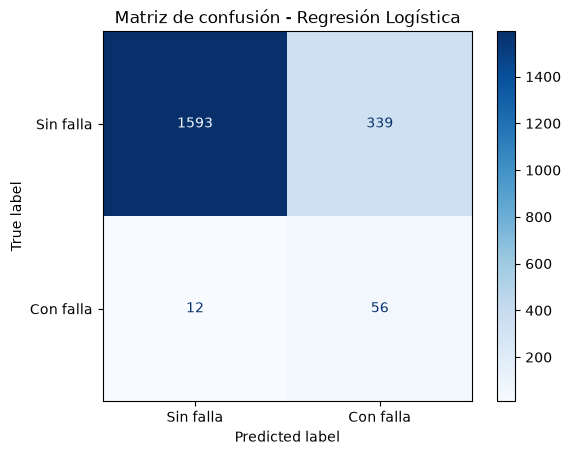

In [13]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcular la matriz de confusión
matriz_logistica = confusion_matrix(y_test, y_pred_logistica)

print("Matriz de confusión - Regresión Logística:")
print(matriz_logistica)

# Visualizar la matriz
ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistica,
    display_labels=["Sin falla", "Con falla"]
).plot(cmap="Blues")

plt.title("Matriz de confusión - Regresión Logística")
plt.show()


In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calcular métricas de Regresión Logística
accuracy_logistica = accuracy_score(y_test, y_pred_logistica)
precision_logistica = precision_score(y_test, y_pred_logistica)
recall_logistica = recall_score(y_test, y_pred_logistica)
f1_logistica = f1_score(y_test, y_pred_logistica)

# Mostrar resultados
print("Evaluación de Regresión Logística:")
print(f"Accuracy: {accuracy_logistica:.4f}")
print(f"Precision: {precision_logistica:.4f}")
print(f"Recall: {recall_logistica:.4f}")
print(f"F1-score: {f1_logistica:.4f}")


Evaluación de Regresión Logística:
Accuracy: 0.8245
Precision: 0.1418
Recall: 0.8235
F1-score: 0.2419



### Interpretación de los resultados

La Regresión Logística alcanzó un recall del 82,35 %, logrando identificar 56 de las 68 fallas reales.

Sin embargo, presentó una precisión baja (14,18 %) y generó 339 falsas alarmas.

Aunque el modelo detecta la mayoría de las fallas, será necesario comparar sus resultados con el Árbol de Decisión para determinar cuál ofrece un mejor equilibrio entre la detección de fallas y las falsas alarmas.



## 4. Modelo 2: Árbol de Decisión

Se entrena un Árbol de Decisión para clasificar las máquinas según presenten o no una falla.

Se utiliza `class_weight="balanced"` para considerar el desbalance entre las clases y `max_depth=5` para limitar la complejidad del árbol y facilitar su interpretación.


In [15]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Crear el modelo de Árbol de Decisión
modelo_arbol = Pipeline(steps=[
    ("preprocesamiento", preprocesador_arbol),
    ("clasificador", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Entrenar el modelo
modelo_arbol.fit(X_train, y_train)

print("Modelo de Árbol de Decisión entrenado correctamente.")


Modelo de Árbol de Decisión entrenado correctamente.


In [16]:

# Realizar predicciones con el Árbol de Decisión
y_pred_arbol = modelo_arbol.predict(X_test)

# Mostrar las primeras 10 predicciones
print("Primeras 10 predicciones:")
print(y_pred_arbol[:10])

# Comparar con los valores reales
print("\nPrimeros 10 valores reales:")
print(y_test.iloc[:10].values)


Primeras 10 predicciones:
[1 0 1 0 1 0 0 0 0 0]

Primeros 10 valores reales:
[0 0 0 0 0 0 0 0 0 0]


Matriz de confusión - Árbol de Decisión:
[[1799  133]
 [   8   60]]


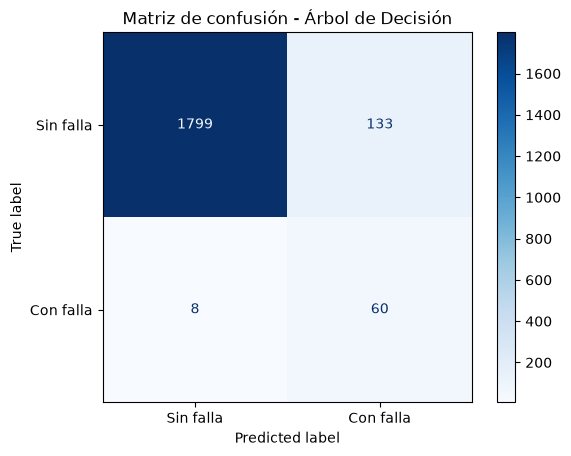

In [17]:

# Calcular la matriz de confusión
matriz_arbol = confusion_matrix(y_test, y_pred_arbol)

print("Matriz de confusión - Árbol de Decisión:")
print(matriz_arbol)

# Visualizar la matriz
ConfusionMatrixDisplay(
    confusion_matrix=matriz_arbol,
    display_labels=["Sin falla", "Con falla"]
).plot(cmap="Blues")

plt.title("Matriz de confusión - Árbol de Decisión")
plt.show()


In [18]:

# Calcular métricas del Árbol de Decisión
accuracy_arbol = accuracy_score(y_test, y_pred_arbol)
precision_arbol = precision_score(y_test, y_pred_arbol)
recall_arbol = recall_score(y_test, y_pred_arbol)
f1_arbol = f1_score(y_test, y_pred_arbol)

# Mostrar resultados
print("Evaluación del Árbol de Decisión:")
print(f"Accuracy: {accuracy_arbol:.4f}")
print(f"Precision: {precision_arbol:.4f}")
print(f"Recall: {recall_arbol:.4f}")
print(f"F1-score: {f1_arbol:.4f}")


Evaluación del Árbol de Decisión:
Accuracy: 0.9295
Precision: 0.3109
Recall: 0.8824
F1-score: 0.4598



### Interpretación de los resultados

El Árbol de Decisión alcanzó un recall del 88,24 %, identificando 60 de las 68 fallas reales.

Además, obtuvo una precisión del 31,09 % y generó 133 falsas alarmas.

Estos resultados muestran una buena capacidad de detección de fallas, aunque todavía existen errores de clasificación. En comparación con la Regresión Logística, el árbol presentó mejores resultados en las métricas evaluadas.



## 5. Comparación de los modelos

Se comparan los resultados de la Regresión Logística y el Árbol de Decisión utilizando las mismas métricas y el mismo conjunto de prueba.

Se dará especial importancia al recall de la clase 1, ya que el objetivo principal es detectar la mayor cantidad posible de fallas reales.


In [19]:

# Crear tabla comparativa de los modelos
comparacion = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Regresión Logística": [
        accuracy_logistica,
        precision_logistica,
        recall_logistica,
        f1_logistica
    ],
    "Árbol de Decisión": [
        accuracy_arbol,
        precision_arbol,
        recall_arbol,
        f1_arbol
    ]
})

# Mostrar los resultados en porcentajes
comparacion["Regresión Logística"] *= 100
comparacion["Árbol de Decisión"] *= 100

display(comparacion.round(2))


,Métrica,Regresión Logística,Árbol de Decisión
0,Accuracy,82.45,92.95
1,Precision,14.18,31.09
2,Recall,82.35,88.24
3,F1-score,24.19,45.98


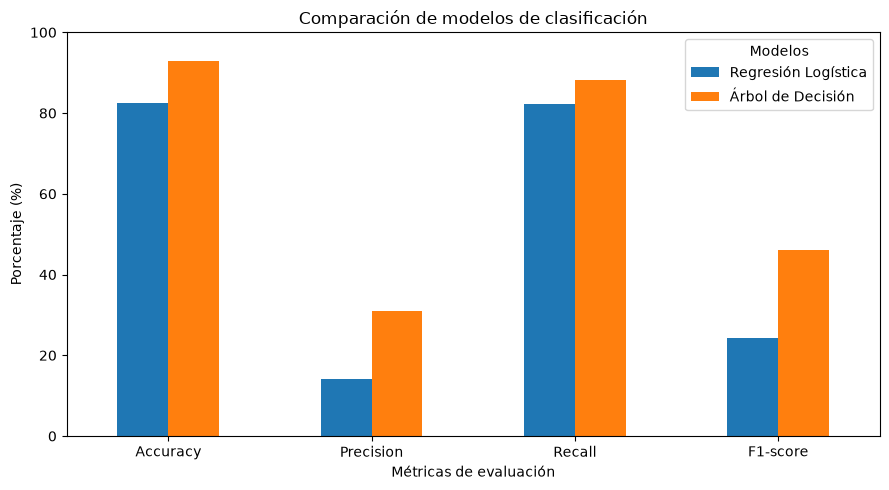

In [20]:

# Gráfico comparativo de las métricas
comparacion.set_index("Métrica").plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Comparación de modelos de clasificación")
plt.ylabel("Porcentaje (%)")
plt.xlabel("Métricas de evaluación")
plt.ylim(0, 100)
plt.legend(title="Modelos")
plt.tight_layout()
plt.show()



### Análisis comparativo

El Árbol de Decisión obtuvo mejores resultados en las cuatro métricas evaluadas.

En particular, logró detectar más fallas reales que la Regresión Logística y redujo considerablemente las falsas alarmas.

Por lo tanto, en las condiciones evaluadas, el Árbol de Decisión resulta más adecuado para nuestro objetivo de identificar fallas industriales.



### Visualización del Árbol de Decisión

Se representan los primeros niveles del árbol para observar las reglas utilizadas en la clasificación de fallas industriales.


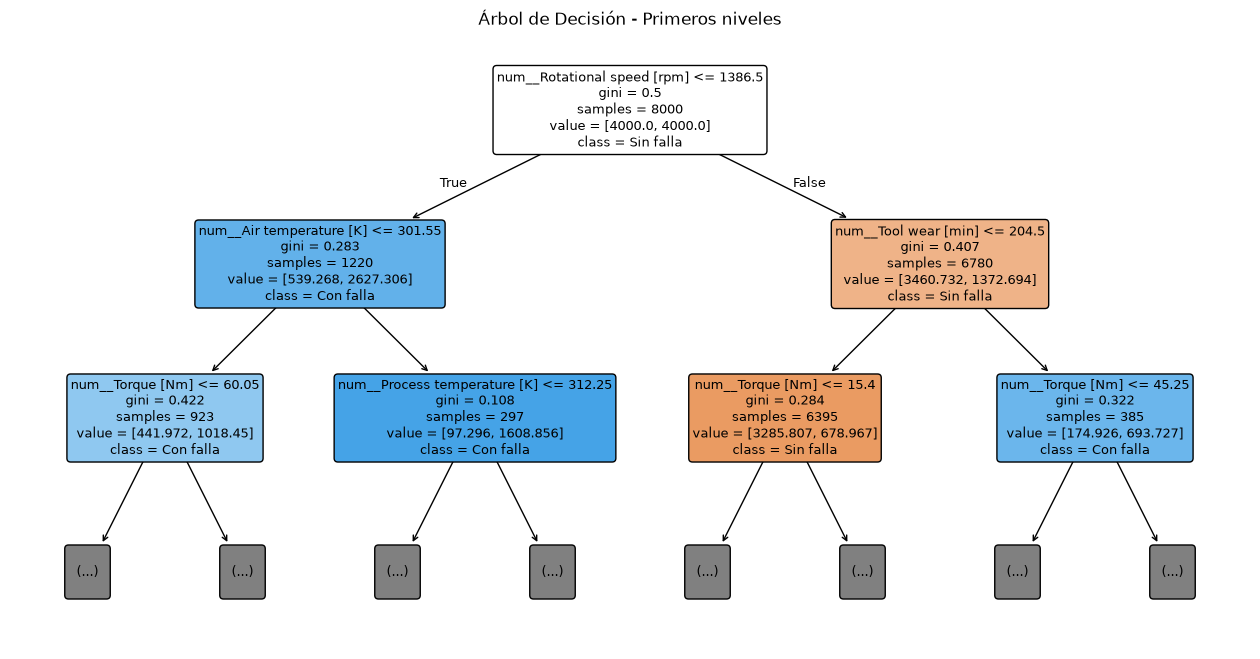

In [21]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Obtener el árbol entrenado
arbol = modelo_arbol.named_steps["clasificador"]

# Obtener los nombres de las variables transformadas
nombres_variables = (
    modelo_arbol.named_steps["preprocesamiento"]
    .get_feature_names_out()
)

# Visualizar los primeros niveles del árbol
plt.figure(figsize=(16, 8))

plot_tree(
    arbol,
    feature_names=nombres_variables,
    class_names=["Sin falla", "Con falla"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)

plt.title("Árbol de Decisión - Primeros niveles")
plt.show()



### Interpretación del Árbol de Decisión

El árbol utiliza inicialmente la velocidad de rotación para dividir los registros y luego considera variables como la temperatura, el desgaste de la herramienta y el torque.

Esto muestra que el modelo combina diferentes condiciones operativas para clasificar las máquinas según la presencia o ausencia de fallas.

La visualización permite comprender algunas de las reglas aprendidas por el modelo, aunque solo se muestran sus primeros niveles.



## 6. Conclusiones

En este trabajo se aplicaron dos modelos de clasificación supervisada, Regresión Logística y Árbol de Decisión, para identificar fallas en máquinas industriales.

Los resultados mostraron que el Árbol de Decisión obtuvo un mejor desempeño en las cuatro métricas evaluadas. En particular, alcanzó un recall del 88,24 %, detectando 60 de las 68 fallas reales, mientras que la Regresión Logística identificó 56.

Además, el árbol generó menos falsas alarmas (133 frente a 339), lo que representa una ventaja para el problema planteado.

Por lo tanto, considero que el Árbol de Decisión es el modelo más adecuado entre los dos evaluados, ya que permite detectar más fallas reales y reducir las clasificaciones incorrectas.

Sin embargo, ambos modelos presentan limitaciones, especialmente en la precisión. Como mejora futura, se podrían ajustar sus hiperparámetros y utilizar validación cruzada para evaluar su capacidad de generalización.
